[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/fingerprint-similarity-guide/blob/main/notebooks/10_clustering_diversity.ipynb)

# 10 · Clustering & Diversity Picking

*Fingerprint & Similarity Guide · Hamza Hentabli, Ph.D. · ~45 min*

Fingerprint choice silently reshapes two everyday tasks: **clustering** a library into chemical families and **picking a diverse subset** for screening or purchase. The same compounds, clustered with different fingerprints, give very different numbers of clusters — and a diverse pick is only as 'diverse' as the fingerprint that judged it. We show both on EGFR compounds.

**Learning objectives.** By the end of this notebook you will be able to:

- run Butina clustering from a fingerprint distance matrix
- see how fingerprint choice changes the number and size of clusters
- pick a maximally diverse subset with the MaxMin algorithm
- understand why a coarse fingerprint under-counts chemical diversity

In [1]:
# Setup: on Google Colab this installs dependencies and clones the repo so the
# cached data and the shared `fsg` helper module are available. Running locally,
# install requirements.txt once and this cell just locates the files.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("FSG_OFFLINE", "0") == "1"   # CI sets this; no notebook needs the network
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "rdkit", "scikit-learn", "scipy", "pandas", "matplotlib"], check=True)
    if not os.path.isdir("fingerprint-similarity-guide"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/fingerprint-similarity-guide.git"], check=True)
    ROOT = "fingerprint-similarity-guide"
else:
    ROOT = ".." if os.path.isdir("../data") else "."
DATA_DIR = os.path.join(ROOT, "data")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
import fsg   # shared fingerprint factory + metrics + evaluation

print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| data:", DATA_DIR)
print("Fingerprints available:", ", ".join(fsg.FP_NAMES))

Colab: False | offline: True | data: ../data
Fingerprints available: ECFP4-1024, ECFP4-2048, ECFP6-2048, ECFP4-counts, FCFP4-2048, RDKit, AtomPair, Torsion, MACCS, Avalon


In [2]:
import numpy as np, pandas as pd
egfr = fsg.load_mols(pd.read_csv(f"{DATA_DIR}/egfr_chembl37_ic50.csv"))
sub = egfr.sample(n=800, random_state=0).reset_index(drop=True)
print(len(sub), "compounds sampled for clustering")

800 compounds sampled for clustering


## 1. Butina clustering

Butina clustering groups molecules so that everything in a cluster is within a Tanimoto **distance** cutoff of the cluster centroid. We cluster the same 800 compounds with three fingerprints at the same cutoff and compare.

In [3]:
from rdkit import DataStructs
from rdkit.ML.Cluster import Butina
def butina_clusters(name, cutoff=0.35):
    fps = fsg.make_fps(name, list(sub["mol"]))
    n = len(fps)
    dists = []
    for i in range(1, n):
        sims = fsg.bulk_similarity("tanimoto", fps[i], fps[:i])
        dists.extend([1 - s for s in sims])
    cs = Butina.ClusterData(dists, n, cutoff, isDistData=True)
    sizes = sorted((len(c) for c in cs), reverse=True)
    return len(cs), sizes[:5]
rows = []
for name in ["ECFP4-2048", "FCFP4-2048", "MACCS"]:
    nc, top = butina_clusters(name)
    rows.append((name, nc, top))
pd.DataFrame(rows, columns=["fingerprint","n_clusters (cutoff 0.35)","5 largest cluster sizes"])

,fingerprint,n_clusters (cutoff 0.35),5 largest cluster sizes
0,ECFP4-2048,486,"[21, 18, 13, 11, 9]"
1,FCFP4-2048,353,"[55, 23, 22, 21, 16]"
2,MACCS,96,"[318, 88, 36, 33, 31]"


Same compounds, same cutoff — **different cluster counts**. The coarse MACCS fingerprint calls more molecules 'close', so it merges them into fewer, larger clusters and reports *less* diversity than ECFP sees. If you pick one representative per cluster for screening, your library size depends entirely on this choice.

## 2. MaxMin diversity selection

To buy/screen a diverse subset, the **MaxMin** picker greedily chooses molecules that are as far as possible from everything already picked. We pick 25 diverse compounds and check their internal diversity under ECFP vs MACCS.

In [4]:
from rdkit.SimDivFilters.rdSimDivPickers import MaxMinPicker
def maxmin_pick(name, k=25):
    fps = fsg.make_fps(name, list(sub["mol"]))
    def dist(i, j): return 1 - fsg.similarity("tanimoto", fps[i], fps[j])
    picker = MaxMinPicker()
    idx = list(picker.LazyPick(dist, len(fps), k, seed=42))
    # mean pairwise distance within the pick (higher = more diverse)
    ds = [dist(idx[a], idx[b]) for a in range(len(idx)) for b in range(a+1, len(idx))]
    return idx, float(np.mean(ds))
for name in ["ECFP4-2048", "MACCS"]:
    idx, mdiv = maxmin_pick(name)
    print(f"{name:12s} mean pairwise distance of 25-compound diverse pick = {mdiv:.3f}")

ECFP4-2048   mean pairwise distance of 25-compound diverse pick = 0.905


MACCS        mean pairwise distance of 25-compound diverse pick = 0.698


Both pickers find a spread-out set, but ECFP's finer resolution yields a pick with higher measured diversity. The lesson repeats: **the fingerprint defines what 'diverse' means.** Use a high-resolution fingerprint (ECFP/FCFP 2,048-bit) when diversity actually matters.

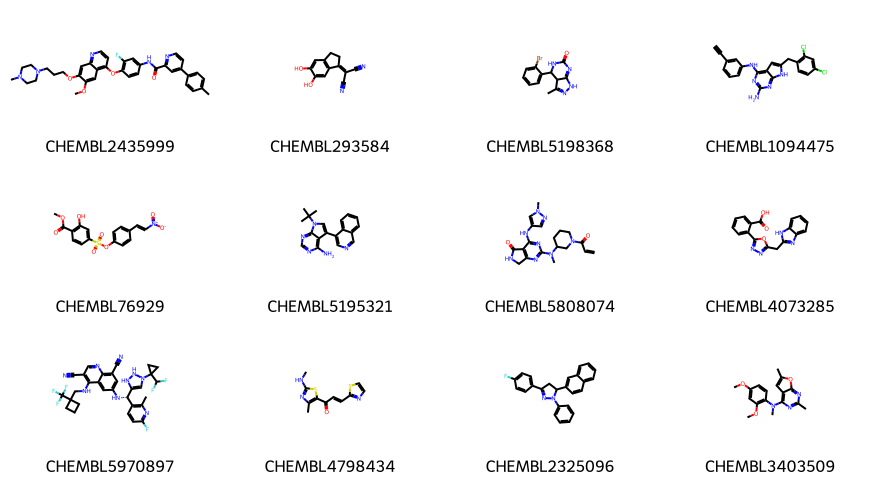

In [5]:
from rdkit.Chem import Draw
idx, _ = maxmin_pick("ECFP4-2048", k=12)
Draw.MolsToGridImage([sub.mol[i] for i in idx], molsPerRow=4, subImgSize=(220,160),
                     legends=[sub.compound_id[i] for i in idx])

## Summary

- Butina **cluster counts depend on the fingerprint**: coarse MACCS merges more, reports less diversity.
- **MaxMin** picks a diverse subset, but the diversity it maximises is the fingerprint's notion of it.
- For clustering and diversity, prefer a high-resolution fingerprint (ECFP/FCFP 2,048-bit).


### ✏️ Exercise 1

Cluster the sample with ECFP4 at cutoffs 0.3 and 0.5. How does the cluster count change?

<details>
<summary><b>Show solution</b></summary>

```python
for c in [0.3, 0.5]:
    print("cutoff", c, "->", butina_clusters("ECFP4-2048", c)[0], "clusters")
```

</details>

### ✏️ Exercise 2

Does AtomPair give more or fewer Butina clusters than ECFP4 at cutoff 0.35?

<details>
<summary><b>Show solution</b></summary>

```python
print("AtomPair:", butina_clusters("AtomPair")[0], "| ECFP4:", butina_clusters("ECFP4-2048")[0])
```

</details>